# M4: Anomaly Score as a Feature on IEEE-CIS
M4 adds an unsupervised anomaly score to the model: an Isolation Forest scores how unusual each transaction looks compared with the earlier transactions, and this score is added as one more feature. It does not use labels, so it can also learn from the newest transactions whose labels are still delayed

M4 is built on M2 (retrained every 7 days on all earlier days, with the 7-day label delay), since M3 (pseudo-labels) did not beat M2 on the validation rows (notebook 07). Everything except the new feature stays the same as M2, so M2 vs M4 shows the effect of the anomaly score on its own

The notebook covers:
- **Anomaly scores** (Section 4): the Isolation Forest score, refitted at each retrain on all transactions before the block start (the same rule as the frequency and `card1` statistic features in M2), and five other versions of the score

- **First version with LightGBM** (Sections 5 and 6): a quick check with the M0 LightGBM settings from notebook 05b, on the 5 tuning blocks of notebook 06 (days 81 to 109) and on the validation rows

- **First version with the tuned CatBoost** (Section 7): the final M2 model from notebook 06 (115 selected features and tuned settings), with and without the anomaly score, on the validation rows

- **Other versions of the score** (Section 8): the first version did not help, so we compare all six versions with the tuned CatBoost on the tuning blocks. The version is chosen on the training days only, without the validation rows

- **Validation of the chosen version** (Section 9): the chosen version is run once on the validation rows

The features come from `04_feature_engineering.ipynb` (saved in `data/processed/`). Only the training and validation rows are used

In [1]:
import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)

pd.set_option("display.max_columns", 100)

SEED = 100   # same seed as notebooks 05 and 06
PROCESSED_DIR = Path("../data/processed")

# everything this notebook trains is saved here, so a rerun loads the finished runs instead of training them again
RUNS_DIR = Path("../data/interim/m4_runs")
RUNS_DIR.mkdir(parents=True, exist_ok=True)

## 2. Data Loading and Preparation
Same as notebook 06 Section 2: only the training and validation rows are kept, categorical columns are pandas categories with `"missing"` as its own value, and the six code columns are turned into text categories

In [2]:
features = pd.read_pickle(PROCESSED_DIR / "ieee_features.pkl")
with open(PROCESSED_DIR / "feature_lists.json") as f:
    feature_lists = json.load(f)

# these columns are stored as numbers, but the numbers are codes with no order
CODE_AS_CATEGORY = ["card1", "card2", "card3", "card5", "addr1", "addr2"]

feature_cols = feature_lists["ieee_feature_cols"]
cat_cols = [c for c in feature_cols if c in feature_lists["ieee_categorical_cols"] or c in CODE_AS_CATEGORY]
num_cols = [c for c in feature_cols if c not in cat_cols]

# keep only the needed columns, and only the training and validation rows
keep = feature_cols + ["isFraud", "ieee_split", "TransactionDT"]
features = features.loc[features["ieee_split"].isin(["train", "validation"]), keep]
features[num_cols] = features[num_cols].astype("float32")
for col in cat_cols:
    if col in CODE_AS_CATEGORY:
        # numbers to text codes e.g. 315.0 becomes "315" and a missing value becomes "missing"
        numbers = pd.to_numeric(features[col], errors="coerce")
        values = numbers.to_numpy(dtype="float64")
        rounded = np.round(values)
        whole = np.isfinite(values) & np.isclose(values, rounded)
        text = np.full(len(features), "missing", dtype=object)
        text[whole] = rounded[whole].astype("int64").astype(str)
        other = np.isfinite(values) & ~whole   # not a whole number => keep the value
        text[other] = numbers.to_numpy(dtype=object)[other]
        features[col] = pd.Series(text, index=features.index).astype("category")
    else:
        features[col] = features[col].astype("object").fillna("missing").astype(str).astype("category")

X, y = features[feature_cols], features["isFraud"]
day = (features["TransactionDT"] // 86400).to_numpy()
is_train = (features["ieee_split"] == "train").to_numpy()
is_val = ~is_train
del features

print("training rows:", is_train.sum(), ", days", day[is_train].min(), "to", day[is_train].max(), "| fraud rate:", round(y[is_train].mean() * 100, 2), "%")
print("validation rows:", is_val.sum(), ", days", day[is_val].min(), "to", day[is_val].max(), "| fraud rate:", round(y[is_val].mean() * 100, 2), "%")
print("features:", len(feature_cols), "| numeric:", len(num_cols), "| categorical (with the 6 code columns):", len(cat_cols))

training rows: 377945 , days 1 to 109 | fraud rate: 3.41 %
validation rows: 94487 , days 109 to 141 | fraud rate: 3.92 %
features: 575 | numeric: 528 | categorical (with the 6 code columns): 47


## 3. M2 Settings
### 3.1 Encodings
Copied from notebook 06 Section 2.1: the frequency and `card1` statistic features are refitted at each retrain on all rows before the block start

In [3]:
FREQ_SOURCE_COLS = [c.removesuffix("_freq") for c in feature_cols if c.endswith("_freq")]
CARD1_STAT_SOURCE_COLS = ["TransactionAmt", "D1", "D10", "D15"]


# count of each value and the card1 statistics, learned from encode_rows only (no labels are used)
def fit_encodings(encode_rows):
    X_enc = X.loc[encode_rows, FREQ_SOURCE_COLS + CARD1_STAT_SOURCE_COLS]
    counts = {col: X_enc[col].value_counts() for col in FREQ_SOURCE_COLS}
    # float64 so the averages are the same as in notebook 04
    stats = {col: X_enc[col].astype("float64").groupby(X_enc["card1"], observed=True).agg(["mean", "std"]) for col in CARD1_STAT_SOURCE_COLS}
    return counts, stats


# replace the encoded columns of X_part (a value not in encode_rows gets a count of 0 and no statistics, as in notebook 04)
def apply_encodings(X_part, encodings):
    counts, stats = encodings
    for col in FREQ_SOURCE_COLS:
        X_part[f"{col}_freq"] = X_part[col].map(counts[col]).astype("float32").fillna(0)
    for col in CARD1_STAT_SOURCE_COLS:
        for stat in ["mean", "std"]:
            X_part[f"{col}_{stat}_by_card1"] = X_part["card1"].map(stats[col][stat]).astype("float32")
    return X_part

### 3.2 Models
- **LightGBM**: the M0 settings from notebook 05b (300 trees, learning rate 0.05, 31 leaves, no class weights), as in M2 LightGBM (notebook 05c)

- **Tuned CatBoost**: the final M2 model from notebook 06: the 115 selected features (Section 4.4) and the tuned settings of trial 13 (Section 5). M3 did not beat this model on the validation rows (notebook 07), so M4 is built on it

The selected features are rebuilt the same way as notebook 07 Section 2: every feature whose permutation PR-AUC drop in notebook 06 is above 0.0003. This needs `permutation_importance_348.pkl` from notebook 06 in `data/interim/m2_tuning/`. If the file is missing, Section 7 is skipped. If `val_m2_tuned_115_trial13.pkl` from notebook 06 is also there, Section 7 loads those M2 scores instead of retraining M2

In [4]:
LGB_SETTINGS = {"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 31, "max_depth": -1,
                "objective": "binary", "random_state": SEED, "n_jobs": -1, "verbosity": -1}

# notebook 06 Section 5, trial 13
CATBOOST_TUNED = {"learning_rate": 0.1, "iterations": 750, "depth": 8, "l2_leaf_reg": 1.5552439007420584,
                  "random_strength": 0.1325358735488683, "bagging_temperature": 0.42109136073074666, "rsm": 0.2810045903691265}

# notebook 06 Section 4.4, rebuilt as in notebook 07 Section 2
TUNING_DIR = Path("../data/interim/m2_tuning")
MIN_DROP = 0.0003
permutation_path = TUNING_DIR / "permutation_importance_348.pkl"


# the files from notebook 06 were saved with a newer pandas version, so a CSV copy is used when the pickle cannot be read
def read_saved(path, **csv_args):
    try:
        return pd.read_pickle(path)
    except Exception:
        csv_path = path.with_suffix(".csv")
        if not csv_path.exists():
            raise
        print(f"{path.name} could not be read with this pandas version => using {csv_path.name}")
        return pd.read_csv(csv_path, **csv_args)


SELECTED_FEATURES = []
if permutation_path.exists() or permutation_path.with_suffix(".csv").exists():
    permutation = read_saved(permutation_path, index_col="feature")
    SELECTED_FEATURES = [c for c in feature_cols if c in permutation.index and permutation.loc[c, "PR-AUC drop"] > MIN_DROP]
    print("selected features:", len(SELECTED_FEATURES), "| categorical:", sum(c in cat_cols for c in SELECTED_FEATURES))
else:
    print(f"{permutation_path} not found => Section 7 (tuned CatBoost) will be skipped")


def make_model(family, cols):
    if family == "LightGBM":
        return lgb.LGBMClassifier(**LGB_SETTINGS), {}
    cat_features = [c for c in cat_cols if c in cols]
    model = CatBoostClassifier(random_seed=SEED, thread_count=-1, verbose=0, allow_writing_files=False, **CATBOOST_TUNED)
    return model, {"cat_features": cat_features}

permutation_importance_348.pkl could not be read with this pandas version => using permutation_importance_348.csv
selected features: 115 | categorical: 21


### 3.3 Evaluation Metrics
The `evaluate` function from notebooks 05 and 06: PR-AUC (main metric), ROC-AUC, precision, recall and F1 at 0.5, precision@100 per day and the confusion matrix counts at 0.5

In [5]:
k = 100
metric_cols = ["PR-AUC", "ROC-AUC", "precision", "recall", "F1", f"precision@{k} per day"]
y_val = y[is_val]
val_day = day[is_val]


def evaluate(name, scores):
    predictions = (scores >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()

    # precision@k per day: share of fraud among each day's k highest scores, averaged over the days
    daily = pd.DataFrame({"day": val_day, "y": y_val.to_numpy(), "score": scores})
    top_k = daily.sort_values("score", ascending=False, kind="stable").groupby("day").head(k)

    return {"model": name,
            "PR-AUC": average_precision_score(y_val, scores),
            "ROC-AUC": roc_auc_score(y_val, scores),
            "precision": precision_score(y_val, predictions, zero_division=0),
            "recall": recall_score(y_val, predictions, zero_division=0),
            "F1": f1_score(y_val, predictions, zero_division=0),
            f"precision@{k} per day": top_k.groupby("day")["y"].mean().mean(),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

## 4. Anomaly Scores
### 4.1 Isolation Forest Score
An Isolation Forest builds random trees that split the data at random values. Unusual transactions are separated after only a few splits, so a short average path means a more anomalous transaction. The score used as a feature is minus sklearn's `score_samples`, so a **higher score means more anomalous**

- **Fitted at each retrain on all transactions before the block start** (labelled or not), the same rule as the M2 encodings. It does not use labels, so the 7-day label delay does not apply to it

- **Inputs**: the numeric features of the model (the categorical columns are left out, since Isolation Forest only splits numbers). Missing values are set to -999, so a missing value is treated as its own extreme value and missingness can still make a transaction look unusual

- **Settings**: 200 trees and 256 rows per tree (the sklearn default), fitted on a random sample of at most 100,000 of the rows before the block start to save memory (each tree only draws 256 rows anyway). Each tree only sees 256 rows, so the training rows are not scored much more "normally" than new rows, even though the forest was fitted on them

- The score is then added as the feature `iforest_score` to both the rows the model trains on and the rows it scores

In [6]:
IFOREST_SETTINGS = {"n_estimators": 200, "max_samples": 256, "random_state": SEED, "n_jobs": -1}
MISSING_VALUE = -999


def anomaly_inputs(rows, cols):
    return X.loc[rows, cols].to_numpy(dtype="float32", na_value=np.nan)


IFOREST_FIT_ROWS = 100_000   # each tree only uses 256 rows, so a random sample of this size is enough to fit the forest


def fit_iforest(fit_rows, cols):
    rows = np.flatnonzero(fit_rows)
    if len(rows) > IFOREST_FIT_ROWS:
        rows = np.sort(np.random.default_rng(SEED).choice(rows, IFOREST_FIT_ROWS, replace=False))
    sample = np.zeros(len(fit_rows), dtype=bool)
    sample[rows] = True
    values = np.nan_to_num(anomaly_inputs(sample, cols), nan=MISSING_VALUE)
    return IsolationForest(**IFOREST_SETTINGS).fit(values)


def iforest_score(forest, rows, cols):
    values = np.nan_to_num(anomaly_inputs(rows, cols), nan=MISSING_VALUE)
    return -forest.score_samples(values)   # higher = more anomalous

### 4.2 Other Versions of the Score
The first version (`iforest_all`) is one score from one forest. The model already has features that describe how unusual a transaction is, so one more summary of the same inputs may add little. The versions below change what the score is compared with, or how it is built. All of them are refitted at each retrain with the same rows the M2 encodings may use, so none of them sees the scored days

| version | what it measures | fitted on |
|---|---|---|
| `iforest_all` | how unusual the transaction is among all earlier transactions (Section 4.1) | all rows before the block start |
| `iforest_legit` | how different it is from transactions that are known to be legitimate | rows with a verified non-fraud label (before the block start minus the 7-day delay) |
| `iforest_recent` | how unusual it is among the newest transactions, whose labels are still hidden | the last 14 days before the block start |
| `iforest_groups` | one score per feature group (`C`, `D`, `V` and the other numeric features), so an unusual value in a small group is not hidden by the other groups | all rows before the block start |
| `pca_error` | reconstruction error of a PCA (a linear autoencoder): how badly the usual relationships between the features describe this transaction | all rows before the block start |
| `combined` | all of the scores above as separate features | as above |

- `iforest_legit` is the only version that uses labels, and only the verified ones the model may already train on

- `pca_error`: missing values are set to the median, each feature is clipped to its 1st and 99th percentiles and standardised, and the PCA keeps the components that explain 90% of the variance. The score is the log of the mean squared reconstruction error

In [7]:
RECENT_DAYS = 14
PCA_VARIANCE = 0.9
ANOMALY_VERSIONS = ["iforest_all", "iforest_legit", "iforest_recent", "iforest_groups", "pca_error", "combined"]


def sample_rows(rows):
    # at most IFOREST_FIT_ROWS of the rows, as a mask
    picked = np.flatnonzero(rows)
    if len(picked) > IFOREST_FIT_ROWS:
        picked = np.sort(np.random.default_rng(SEED).choice(picked, IFOREST_FIT_ROWS, replace=False))
    sample = np.zeros(len(rows), dtype=bool)
    sample[picked] = True
    return sample


# each scorer is fitted on fit_on and returns a function that scores any rows
def iforest_scorer(fit_on, cols):
    forest = fit_iforest(fit_on, cols)
    return lambda rows: iforest_score(forest, rows, cols)


def pca_scorer(fit_on, cols):
    raw = anomaly_inputs(sample_rows(fit_on), cols).astype("float64")
    keep = np.isfinite(raw).any(axis=0)   # a column with no values in the sample is left out
    median = np.nanmedian(raw[:, keep], axis=0)
    low, high = np.nanpercentile(raw[:, keep], [1, 99], axis=0)

    def prepare(v):
        v = v[:, keep]
        v = np.where(np.isnan(v), median, v)
        return np.clip(v, low, high)

    prepared = prepare(raw)
    mean, std = prepared.mean(axis=0), prepared.std(axis=0)
    std[std == 0] = 1
    pca = PCA(n_components=PCA_VARIANCE, svd_solver="full").fit((prepared - mean) / std)

    def score(rows):
        z = (prepare(anomaly_inputs(rows, cols).astype("float64")) - mean) / std
        error = ((z - pca.inverse_transform(pca.transform(z))) ** 2).mean(axis=1)
        return np.log1p(error)   # higher = more anomalous
    return score


def feature_groups(cols):
    groups = {"C": [], "D": [], "V": [], "other": []}
    for col in cols:
        match = re.fullmatch(r"([CDV])\d+", col)
        groups[match.group(1) if match else "other"].append(col)
    return {name: group for name, group in groups.items() if len(group) >= 2}


# the scorers of one version for one block, as {feature name: scorer}
def anomaly_scorers(version, block_start, encode_rows, fit_rows, cols):
    scorers = {}
    if version in ("iforest_all", "combined"):
        scorers["iforest_score"] = iforest_scorer(encode_rows, cols)
    if version in ("iforest_legit", "combined"):
        scorers["iforest_legit"] = iforest_scorer(fit_rows & (y == 0).to_numpy(), cols)
    if version in ("iforest_recent", "combined"):
        scorers["iforest_recent"] = iforest_scorer(encode_rows & (day >= block_start - RECENT_DAYS), cols)
    if version in ("iforest_groups", "combined"):
        for name, group in feature_groups(cols).items():
            scorers[f"iforest_group_{name}"] = iforest_scorer(encode_rows, group)
    if version in ("pca_error", "combined"):
        scorers["pca_error"] = pca_scorer(encode_rows, cols)
    if not scorers:
        raise ValueError(f"unknown anomaly score version: {version}")
    return scorers

## 5. Tuning Blocks: Does the First Version Help on the Training Days?
Same 5 tuning blocks as notebook 06 Section 3: each block retrains on the labelled transactions before the block start minus 7 days and scores the next 7 days, using training rows only. We compare LightGBM with and without `iforest_score`, and also look at how well the score alone ranks fraud (PR-AUC of the score itself)

In [8]:
LABEL_DELAY_DAYS = 7
FREQUENCY = 7
BLOCK_STARTS = [81, 88, 95, 102, 109]
labelled_rows = is_train | is_val


def block_scores(family, cols, version, row_pool, starts, last_day, run_name):
    # retrain every FREQUENCY days from each start, on the rows of row_pool before the start minus the delay
    # version is None for M2, or one of ANOMALY_VERSIONS for M4
    path = RUNS_DIR / f"{run_name}.pkl"
    if path.exists():
        return pd.read_pickle(path)

    start_time = time.time()
    num_inputs = [c for c in cols if c in num_cols]
    out = []
    for block_start in starts:
        block = row_pool & (day >= block_start) & (day < min(block_start + FREQUENCY, last_day + 1))
        if not block.any():
            continue
        fit_rows = row_pool & (day < block_start - LABEL_DELAY_DAYS)
        encode_rows = row_pool & (day < block_start)
        encodings = fit_encodings(encode_rows)
        X_fit = apply_encodings(X[fit_rows].copy(), encodings)[cols]
        X_block = apply_encodings(X[block].copy(), encodings)[cols]

        block_out = {"block": block_start}
        if version is not None:
            fit_scores = {}
            for name, scorer in anomaly_scorers(version, block_start, encode_rows, fit_rows, num_inputs).items():
                fit_scores[name] = scorer(fit_rows)
                block_out[name] = scorer(block)
            X_fit = X_fit.assign(**fit_scores)
            X_block = X_block.assign(**{name: block_out[name] for name in fit_scores})
        else:
            block_out["iforest_score"] = np.nan

        model, fit_args = make_model(family, cols)
        model.fit(X_fit, y[fit_rows], **fit_args)
        block_out["score"] = model.predict_proba(X_block)[:, 1]
        out.append(pd.DataFrame(block_out, index=X.index[block]))
        del model, X_fit

    out = pd.concat(out)
    out.to_pickle(path)
    print(f"{run_name}: {time.time() - start_time:.0f}s")
    return out


tuning = {}
TRAIN_LAST_DAY = int(day[is_train].max())
tuning["M2 LightGBM"] = block_scores("LightGBM", feature_cols, None, is_train, BLOCK_STARTS, TRAIN_LAST_DAY, "tuning_m2_LightGBM_all")
tuning["M4 LightGBM"] = block_scores("LightGBM", feature_cols, "iforest_all", is_train, BLOCK_STARTS, TRAIN_LAST_DAY, "tuning_m4_LightGBM_all")

y_tuning = y.loc[tuning["M2 LightGBM"].index]
rows = []
for name, out in tuning.items():
    row = {"model": name, "pooled PR-AUC": average_precision_score(y_tuning, out["score"])}
    for block_start in BLOCK_STARTS:
        in_block = out["block"] == block_start
        row[f"block {block_start}"] = average_precision_score(y_tuning[in_block.to_numpy()], out.loc[in_block, "score"])
    rows.append(row)
anomaly_alone = tuning["M4 LightGBM"]["iforest_score"]
rows.append({"model": "iforest_score alone", "pooled PR-AUC": average_precision_score(y_tuning, anomaly_alone)})
display(pd.DataFrame(rows).set_index("model").round(4))
print(f"fraud rate in the tuning blocks: {y_tuning.mean():.4f} (PR-AUC of a random ranking)")
print(f"ROC-AUC of iforest_score alone: {roc_auc_score(y_tuning, anomaly_alone):.4f}")

,pooled PR-AUC,block 81,block 88,block 95,block 102,block 109
model,,,,,,
M2 LightGBM,0.5444,0.5667,0.5256,0.4863,0.5994,0.4887
M4 LightGBM,0.5491,0.5896,0.5244,0.4828,0.5996,0.5125
iforest_score alone,0.1052,NaN,NaN,NaN,NaN,NaN


fraud rate in the tuning blocks: 0.0359 (PR-AUC of a random ranking)
ROC-AUC of iforest_score alone: 0.7589


**Takeaway: Tuning Blocks**
- **The anomaly score carries signal on its own**: `iforest_score` alone has a PR-AUC of 0.105 on the tuning blocks, about 2.9 times the fraud rate (0.036), and a ROC-AUC of 0.759, without using any labels

- **BUT adding it to LightGBM only helps a little**: the pooled PR-AUC goes from 0.5444 to 0.5491 (+0.0047), which is within the seed range of 0.006 measured in notebook 05

- The gain is not consistent across the blocks: +0.023 (block 81) and +0.024 (block 109) **BUT** -0.001, -0.0035 and +0.0002 for the 3 blocks in between. Block 109 only covers part of day 109, so it has the fewest rows => most of the pooled gain comes from one full block

- => the score does not hurt on the training days, so we keep it for the validation check, **BUT** most of what it captures seems to be already covered by the existing features (e.g. the `C` counts, the missingness and the frequency features also describe how unusual a transaction is)

## 6. Validation: First Version with LightGBM
Same retraining as M2 on the validation rows (notebook 05c): every 7 days from day 109, on all earlier labelled days minus the 7-day delay. The M2 LightGBM row is rerun here with the same code, so the only difference between the two rows is `iforest_score`

In [9]:
VAL_FIRST_DAY, VAL_LAST_DAY = int(day[is_val].min()), int(day[is_val].max())
val_starts = list(range(VAL_FIRST_DAY, VAL_LAST_DAY + 1, FREQUENCY))


def validation_scores(family, cols, version, run_name):
    out = block_scores(family, cols, version, labelled_rows, val_starts, VAL_LAST_DAY, run_name)
    return out.loc[X.index[is_val], "score"].to_numpy()


val_scores = {}
val_scores["M2 LightGBM"] = validation_scores("LightGBM", feature_cols, None, "val_m2_LightGBM_all")
val_scores["M4 LightGBM"] = validation_scores("LightGBM", feature_cols, "iforest_all", "val_m4_LightGBM_all")
print(f"M2 LightGBM PR-AUC here: {average_precision_score(y_val, val_scores['M2 LightGBM']):.4f} (notebook 05c: 0.6187)")

M2 LightGBM PR-AUC here: 0.6187 (notebook 05c: 0.6187)


## 7. Validation: First Version with the Tuned CatBoost
The final M2 CatBoost from notebook 06 (115 selected features and the tuned settings), with and without `iforest_score`. The Isolation Forest uses the numeric features among the 115 selected ones. Each run trains 5 CatBoost models, which took about 38 minutes in notebook 06. If the M2 scores from notebook 06 are available, only the M4 run is trained (the runs are saved, so a rerun only loads them)

In [10]:
if SELECTED_FEATURES:
    notebook06_path = TUNING_DIR / "val_m2_tuned_115_trial13.pkl"
    if notebook06_path.exists() or notebook06_path.with_suffix(".csv").exists():
        # the same M2 run as notebook 06 Section 6, so we load it instead of retraining
        saved = read_saved(notebook06_path, index_col="row")
        if isinstance(saved, pd.DataFrame):
            saved = saved["score"]
        val_scores["M2 CatBoost (tuned)"] = saved.loc[X.index[is_val]].to_numpy()
        print("M2 CatBoost (tuned): loaded from notebook 06")
    else:
        val_scores["M2 CatBoost (tuned)"] = validation_scores("CatBoost", SELECTED_FEATURES, None, "val_m2_CatBoost_tuned")
    val_scores["M4 CatBoost (tuned), iforest_all"] = validation_scores("CatBoost", SELECTED_FEATURES, "iforest_all", "val_m4_CatBoost_tuned")
    print(f"M2 CatBoost (tuned) PR-AUC: {average_precision_score(y_val, val_scores['M2 CatBoost (tuned)']):.4f} (notebook 06: 0.6673)")
else:
    print("skipped: put permutation_importance_348.pkl from notebook 06 in data/interim/m2_tuning/")

M2 CatBoost (tuned): loaded from notebook 06


M2 CatBoost (tuned) PR-AUC: 0.6673 (notebook 06: 0.6673)


## 8. Other Versions of the Score on the Tuning Blocks
The first version did not help the tuned CatBoost on the validation rows (Section 7). Before deciding that an anomaly score does not help, we check whether this depends on how the score is built: every version from Section 4.2 is added to the tuned CatBoost and scored on the 5 tuning blocks of notebook 06 (days 81 to 109, training rows only)

- The M2 row is the same model without an anomaly score. Notebook 06 got a pooled PR-AUC of 0.5868 for it (Section 5, trial 13), so it is also a check that this notebook retrains M2 the same way

- **The version is chosen here, on the training days**: the version with the highest pooled PR-AUC is the one that goes to the validation rows in Section 9. The validation rows are not used to choose

- The seed range of CatBoost is about 0.006 PR-AUC (notebook 05 Section 5.6), so a smaller difference between two rows is not a real difference. We also count in how many of the 5 blocks each version is above M2

Each row trains 5 CatBoost models. The runs are saved, so a rerun only loads them, and `VERSIONS_TO_RUN` can be shortened to save time

In [11]:
VERSIONS_TO_RUN = ["combined", "iforest_legit", "pca_error", "iforest_recent", "iforest_groups", "iforest_all"]

best_version = None
if SELECTED_FEATURES:
    cb_tuning = {"M2 (no anomaly score)": block_scores("CatBoost", SELECTED_FEATURES, None, is_train, BLOCK_STARTS, TRAIN_LAST_DAY, "tuning_m2_CatBoost_tuned")}
    for version in VERSIONS_TO_RUN:
        cb_tuning[version] = block_scores("CatBoost", SELECTED_FEATURES, version, is_train, BLOCK_STARTS, TRAIN_LAST_DAY, f"tuning_m4_CatBoost_tuned_{version}")

    y_cb_tuning = y.loc[cb_tuning["M2 (no anomaly score)"].index]
    rows = []
    for name, out in cb_tuning.items():
        row = {"model": name, "pooled PR-AUC": average_precision_score(y_cb_tuning, out["score"])}
        for block_start in BLOCK_STARTS:
            in_block = (out["block"] == block_start).to_numpy()
            row[f"block {block_start}"] = average_precision_score(y_cb_tuning[in_block], out.loc[in_block, "score"])
        rows.append(row)
    cb_table = pd.DataFrame(rows).set_index("model")
    m2_row = cb_table.loc["M2 (no anomaly score)"]
    block_cols = [f"block {block_start}" for block_start in BLOCK_STARTS]
    cb_table["change vs M2"] = cb_table["pooled PR-AUC"] - m2_row["pooled PR-AUC"]
    cb_table["blocks above M2"] = (cb_table[block_cols] > m2_row[block_cols]).sum(axis=1)
    display(cb_table.round(4))
    print(f"M2 pooled PR-AUC here: {m2_row['pooled PR-AUC']:.4f} (notebook 06, trial 13: 0.5868)")

    best_version = cb_table.drop(index="M2 (no anomaly score)")["pooled PR-AUC"].idxmax()
    print(f"version with the highest pooled PR-AUC: {best_version} ({cb_table.loc[best_version, 'change vs M2']:+.4f} vs M2)")

    # how well each score ranks fraud on its own (no model), from the scores saved with the runs
    alone = {}
    for name, out in cb_tuning.items():
        for col in out.columns:
            if col not in ("block", "score") and out[col].notna().all():
                alone[col] = {"PR-AUC alone": average_precision_score(y_cb_tuning, out[col]), "ROC-AUC alone": roc_auc_score(y_cb_tuning, out[col])}
    print(f"each score on its own (fraud rate {y_cb_tuning.mean():.4f}):")
    display(pd.DataFrame(alone).T.sort_values("PR-AUC alone", ascending=False).round(4))
else:
    print("skipped: put permutation_importance_348.pkl from notebook 06 in data/interim/m2_tuning/")

tuning_m2_CatBoost_tuned: 711s


tuning_m4_CatBoost_tuned_combined: 857s


tuning_m4_CatBoost_tuned_iforest_legit: 779s


tuning_m4_CatBoost_tuned_pca_error: 775s


tuning_m4_CatBoost_tuned_iforest_recent: 787s


tuning_m4_CatBoost_tuned_iforest_groups: 913s


tuning_m4_CatBoost_tuned_iforest_all: 858s


,pooled PR-AUC,block 81,block 88,block 95,block 102,block 109,change vs M2,blocks above M2
model,,,,,,,,
M2 (no anomaly score),0.5868,0.6090,0.5666,0.5154,0.6559,0.5309,0.0000,0
combined,0.5752,0.5980,0.5582,0.5010,0.6479,0.4941,-0.0116,0
iforest_legit,0.5827,0.6026,0.5578,0.5119,0.6580,0.5387,-0.0041,2
pca_error,0.5847,0.6010,0.5597,0.5275,0.6506,0.4960,-0.0021,1
iforest_recent,0.5764,0.5950,0.5550,0.5072,0.6487,0.5329,-0.0104,1
iforest_groups,0.5755,0.5812,0.5485,0.5133,0.6587,0.5131,-0.0113,1
iforest_all,0.5768,0.5909,0.5481,0.5178,0.6502,0.5102,-0.0100,1


M2 pooled PR-AUC here: 0.5868 (notebook 06, trial 13: 0.5868)
version with the highest pooled PR-AUC: pca_error (-0.0021 vs M2)


each score on its own (fraud rate 0.0359):


,PR-AUC alone,ROC-AUC alone
pca_error,0.1503,0.7373
iforest_recent,0.1334,0.7440
iforest_legit,0.1279,0.7501
iforest_score,0.1236,0.7467
iforest_group_V,0.1161,0.7642
iforest_group_C,0.1011,0.6789
iforest_group_other,0.0786,0.6797
iforest_group_D,0.0510,0.5940


**Takeaway: Other Versions on the Tuning Blocks**
- **No version beats M2 with the tuned CatBoost**: every version has a lower pooled PR-AUC than M2 (0.5868). The closest is `pca_error` (0.5847, -0.0021), followed by `iforest_legit` (0.5827, -0.0041). The others lose about 0.010 to 0.012

- **The gaps are mostly negative block by block too**: no version is above M2 in more than 2 of the 5 blocks, and `combined` is below M2 in all 5. Adding more scores does not help; `combined` is the worst version

- **Each score still carries signal on its own**: `pca_error` has the highest PR-AUC alone (0.150, about 4.2 times the fraud rate), and the V group is the strongest of the 4 groups (0.116). So the problem is not that the scores are empty, but that the tuned CatBoost already picks up the same pattern from the 115 features

- Since the differences are within or close to the seed range (0.006), `pca_error` is taken to validation only as the best candidate, not as a version expected to win

## 9. Validation: Chosen Version with the Tuned CatBoost
The version chosen in Section 8 is run once on the validation rows, with the same retraining as M2. If the chosen version is the first one (`iforest_all`), this is the run from Section 7

In [12]:
if SELECTED_FEATURES and best_version is not None and best_version != "iforest_all":
    val_scores[f"M4 CatBoost (tuned), {best_version}"] = validation_scores("CatBoost", SELECTED_FEATURES, best_version, f"val_m4_CatBoost_tuned_{best_version}")
print("chosen version:", best_version)

val_m4_CatBoost_tuned_pca_error: 1071s
chosen version: pca_error


## 10. Results
### 10.1 M2 vs M4

In [13]:
results = pd.DataFrame([evaluate(name, scores) for name, scores in val_scores.items()]).set_index("model")
display(results.round(4))

# each M4 row against the M2 row of the same family
rows = []
for name in results.index:
    if name.startswith("M4"):
        m2_name = "M2 LightGBM" if "LightGBM" in name else "M2 CatBoost (tuned)"
        rows.append({"model": name} | {metric: results.loc[name, metric] - results.loc[m2_name, metric] for metric in metric_cols})
print("change from M2 to M4 (M4 - M2):")
display(pd.DataFrame(rows).set_index("model").round(4))

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M2 LightGBM,0.6187,0.9229,0.8550,0.3979,0.5431,0.6130,1474,250,2230,90533
M4 LightGBM,0.6206,0.9224,0.8562,0.3988,0.5441,0.6136,1477,248,2227,90535
M2 CatBoost (tuned),0.6673,0.9374,0.8589,0.4619,0.6008,0.6467,1711,281,1993,90502
"M4 CatBoost (tuned), iforest_all",0.6633,0.9381,0.8469,0.4646,0.6001,0.6376,1721,311,1983,90472
"M4 CatBoost (tuned), pca_error",0.6572,0.9362,0.8456,0.4568,0.5932,0.6400,1692,309,2012,90474


change from M2 to M4 (M4 - M2):


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day
model,,,,,,
M4 LightGBM,0.0019,-0.0005,0.0012,0.0008,0.0010,0.0006
"M4 CatBoost (tuned), iforest_all",-0.0040,0.0007,-0.0120,0.0027,-0.0007,-0.0091
"M4 CatBoost (tuned), pca_error",-0.0101,-0.0012,-0.0134,-0.0051,-0.0076,-0.0067


### 10.2 PR-AUC per Validation Week

In [14]:
week = (val_day - VAL_FIRST_DAY) // 7
weekly = []
for name, scores in val_scores.items():
    for w in np.unique(week):
        rows_w = week == w
        weekly.append({"model": name, "week": int(w) + 1, "PR-AUC": average_precision_score(y_val.to_numpy()[rows_w], scores[rows_w])})
weekly = pd.DataFrame(weekly)
display(weekly.pivot_table(index="model", columns="week", values="PR-AUC", sort=False).round(4))

week,1,2,3,4,5
model,,,,,
M2 LightGBM,0.6391,0.6033,0.6637,0.6148,0.5109
M4 LightGBM,0.6404,0.6043,0.6661,0.6190,0.5118
M2 CatBoost (tuned),0.6924,0.6394,0.6983,0.6805,0.6082
"M4 CatBoost (tuned), iforest_all",0.6881,0.6419,0.7016,0.6643,0.5905
"M4 CatBoost (tuned), pca_error",0.6867,0.6254,0.6968,0.6609,0.5982


### 10.3 The First Version of the Score on Its Own
How well the anomaly score ranks fraud on its own, and the fraud rate by anomaly-score decile on the validation rows

iforest_score alone on the validation rows: PR-AUC 0.1171, ROC-AUC 0.7673 (fraud rate 0.0392)


decile,1,2,3,4,5,6,7,8,9,10
fraud rate,0.0097,0.0117,0.0108,0.0131,0.0189,0.0193,0.0292,0.05,0.0702,0.1591
rows,9449.0000,9449.0000,9448.0000,9449.0000,9449.0000,9448.0000,9449.0000,9448.00,9449.0000,9449.0000


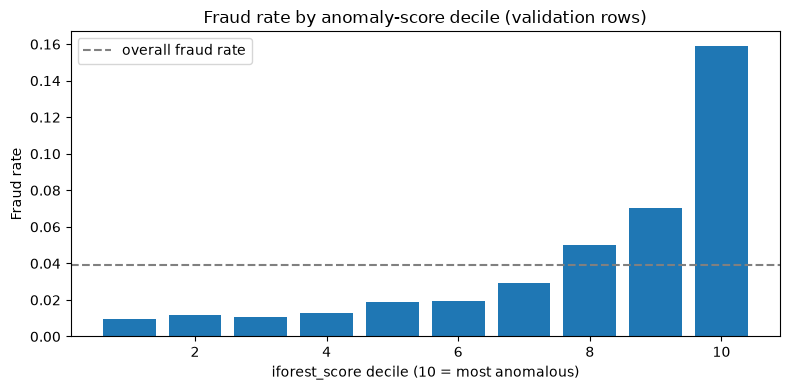

In [15]:
val_anomaly = block_scores("LightGBM", feature_cols, "iforest_all", labelled_rows, val_starts, VAL_LAST_DAY, "val_m4_LightGBM_all").loc[X.index[is_val], "iforest_score"]
print(f"iforest_score alone on the validation rows: PR-AUC {average_precision_score(y_val, val_anomaly):.4f}, "
      f"ROC-AUC {roc_auc_score(y_val, val_anomaly):.4f} (fraud rate {y_val.mean():.4f})")

deciles = pd.qcut(val_anomaly.rank(method="first"), 10, labels=range(1, 11))
by_decile = pd.DataFrame({"decile": deciles.to_numpy(), "fraud": y_val.to_numpy()}).groupby("decile", observed=True)["fraud"].agg(["mean", "size"])
by_decile.columns = ["fraud rate", "rows"]
display(by_decile.round(4).T)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_decile.index.astype(int), by_decile["fraud rate"])
ax.axhline(y_val.mean(), color="grey", linestyle="--", label="overall fraud rate")
ax.set_xlabel("iforest_score decile (10 = most anomalous)")
ax.set_ylabel("Fraud rate")
ax.set_title("Fraud rate by anomaly-score decile (validation rows)")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Takeaways
- **M4 does not improve on M2 for IEEE-CIS**: on validation, the tuned CatBoost drops from 0.6673 to 0.6633 with `iforest_all` (-0.004) and to 0.6572 with `pca_error` (-0.010). With `pca_error`, all 5 validation weeks are lower than M2. Precision@100 per day also drops by 0.007 to 0.009

- **The only gain is with LightGBM, and it is too small to count**: 0.6187 to 0.6206 (+0.002), within the seed range. The weaker model can use the extra score a little, the tuned CatBoost cannot

- **Why**: the anomaly score clearly ranks fraud higher (in the top validation decile the fraud rate is 0.159, against 0.010 in the bottom decile), **BUT** the same information is already in the features the model uses. Isolation Forest and PCA only see the features, so they cannot add anything a well-tuned tree model on those features has not already learnt

- **This matches the earlier results**: M3 (pseudo-labels) also did not beat M2, and notebook 05d showed the performance decay follows time since training (concept drift) rather than feature shift. Adding unsupervised signals does not fix concept drift; periodic retraining on recent labels (M2) is what helps

- **Final IEEE-CIS model: M2 with the tuned CatBoost (validation PR-AUC 0.6673)**. M4 is reported as a tested alternative that did not help